#  Exploratory Data Analysis (EDA)
## Objectives:
- Analyze shipping mode vs. delay severity.
- Examine regional delay patterns across geographic markets.
- Analyze correlation between order value, profit, discount rates, and delay risks.
  

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/SuplyChainDelay/data/syndelay_v1.csv")

In [4]:
df

,payment_type,profit_per_order,sales_per_customer,category_id,category_name,customer_city,customer_country,customer_id,customer_segment,customer_state,...,order_region,order_state,order_status,product_card_id,product_category_id,product_name,product_price,shipping_date,shipping_mode,label
0,PAYMENT,-32.924488,278.950000,38,Kids' Golf Clubs,Caguas,Puerto Rico,12446.5625,Corporate,PR,...,Caribbean,Martinique,PENDING_PAYMENT,858,38,GolfBuddy VT3 GPS Watch,129.99,42177.500,Second Class,2
1,DEBIT,107.874500,263.980000,17,Cleats,Caguas,Puerto Rico,7782.0170,Corporate,PR,...,East Africa,Copperbelt,COMPLETE,365,17,Perfect Fitness Perfect Rip Deck,59.99,42502.390,Same Day,1
2,PAYMENT,35.770718,109.650130,17,Cleats,Caguas,Puerto Rico,7378.1113,Consumer,PR,...,West Asia,Ankara,PENDING_PAYMENT,365,17,Perfect Fitness Perfect Rip Deck,59.99,42951.266,Standard Class,0
3,PAYMENT,43.587560,113.090000,18,Men's Footwear,Caguas,Puerto Rico,1448.6765,Consumer,PR,...,Central America,Francisco Morazan,PENDING_PAYMENT,403,18,Nike Men's CJ Elite 2 TD Football Cleat,129.99,42181.900,Second Class,2
4,PAYMENT,49.804802,191.980900,9,Cardio Equipment,Madison,EE. UU.,5123.5254,Corporate,WI,...,Central America,Leon,PENDING_PAYMENT,191,9,Nike Men's Free 5.0+ Running Shoe,99.99,42632.820,Standard Class,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155483,TRANSFER,-57.828900,163.990000,29,Shop By Sport,Milford,EE. UU.,10456.0340,Consumer,CT,...,Central America,Mexico,PROCESSING,627,29,Under Armour Girls' Toddler Spine Surge Runni,39.99,42715.277,First Class,2
155484,DEBIT,125.350204,392.006440,45,Fishing,Saint Louis,EE. UU.,5690.0977,Consumer,MO,...,Southeast Asia,Riau,COMPLETE,1004,45,Field & Stream Sportsman 16 Gun Fire Safe,399.98,42411.030,Second Class,1
155485,TRANSFER,49.595863,104.378204,67,DVDs,Chicago,EE. UU.,11397.8750,Consumer,IL,...,Southern Europe,Apulia,PENDING,1354,67,DVDs,29.99,42037.516,Standard Class,2
155486,CASH,80.183090,293.980000,43,Camping & Hiking,Provo,EE. UU.,7845.9480,Consumer,UT,...,Southern Europe,Lombardy,CLOSED,957,43,Diamondback Women's Serene Classic Comfort Bi,299.98,42656.656,Second Class,2


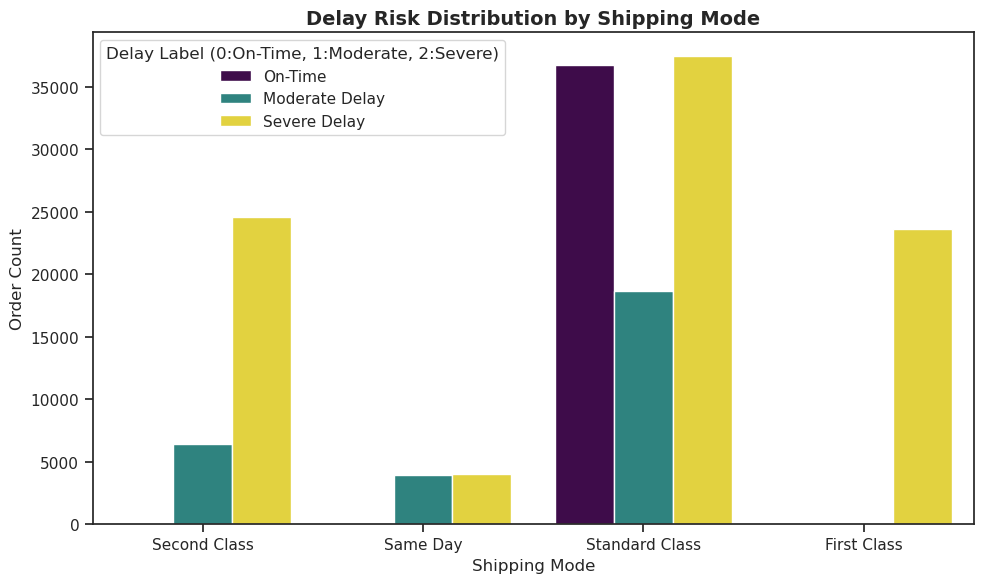

In [12]:
# 1. Shipping Mode vs Delay Risk

sns.set_theme(style='ticks')
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='shipping_mode', hue='label', palette='viridis')
plt.title('Delay Risk Distribution by Shipping Mode', fontsize=14, fontweight='bold')
plt.xlabel('Shipping Mode', fontsize=12)
plt.ylabel('Order Count', fontsize=12)
plt.legend(title='Delay Label (0:On-Time, 1:Moderate, 2:Severe)', labels=['On-Time', 'Moderate Delay', 'Severe Delay'])
plt.tight_layout()
plt.show()

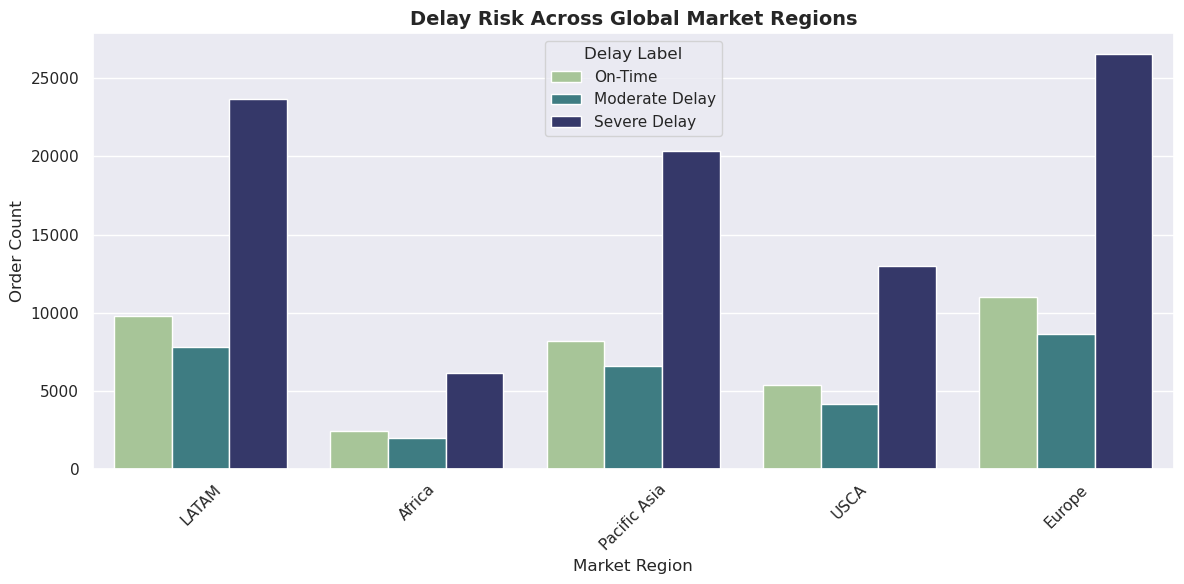

In [6]:
# 2. Delay Risk by Market Region
sns.set_theme(style='darkgrid')
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='market', hue='label', palette='crest')
plt.title('Delay Risk Across Global Market Regions', fontsize=14, fontweight='bold')
plt.xlabel('Market Region', fontsize=12)
plt.ylabel('Order Count', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Delay Label', labels=['On-Time', 'Moderate Delay', 'Severe Delay'])
plt.tight_layout()
plt.show()

/tmp/ipykernel_22105/2460843903.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='profit_per_order', palette='Greens')


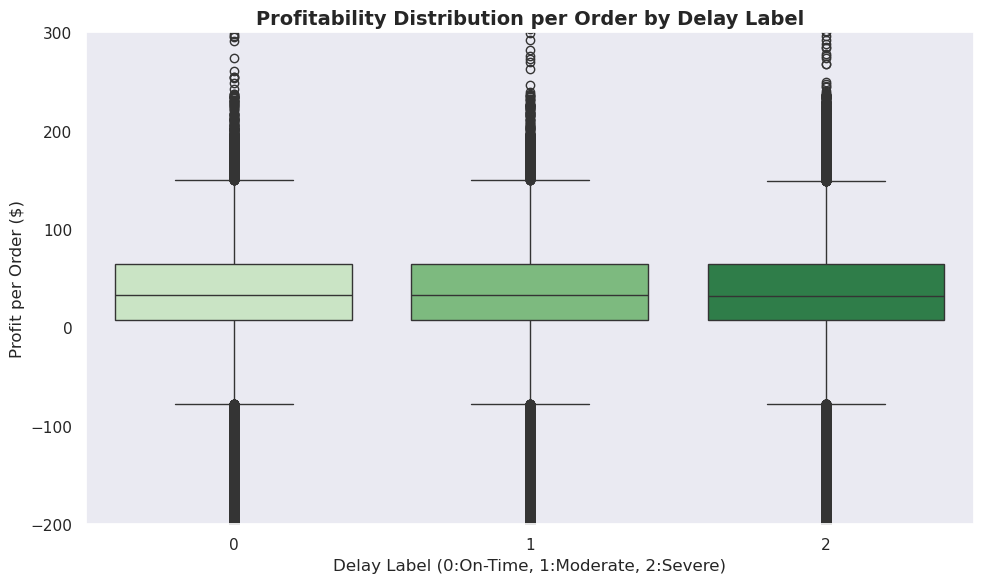

In [7]:
# 3. Profit per Order Distribution by Delay Label
sns.set_theme(style='dark')
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='label', y='profit_per_order', palette='Greens')
plt.title('Profitability Distribution per Order by Delay Label', fontsize=14, fontweight='bold')
plt.xlabel('Delay Label (0:On-Time, 1:Moderate, 2:Severe)', fontsize=12)
plt.ylabel('Profit per Order ($)', fontsize=12)
plt.ylim(-200, 300)
plt.tight_layout()
plt.show()

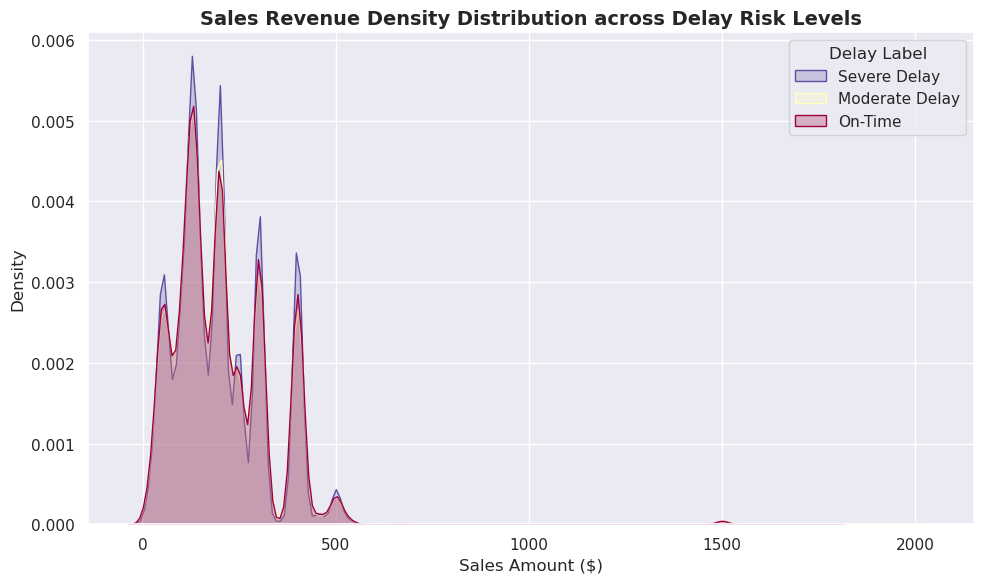

In [8]:
# 4. Sales Density across Delay Risk Levels
sns.set_theme(style='darkgrid')
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, hue='label', x='sales', common_norm=False, fill=True, palette='Spectral')
plt.title('Sales Revenue Density Distribution across Delay Risk Levels', fontsize=14, fontweight='bold')
plt.xlabel('Sales Amount ($)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(title='Delay Label', labels=['Severe Delay', 'Moderate Delay', 'On-Time'])
plt.tight_layout()
plt.show()

/tmp/ipykernel_22105/2403419724.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=department_counts, x='department_name', y='count', palette='crest')


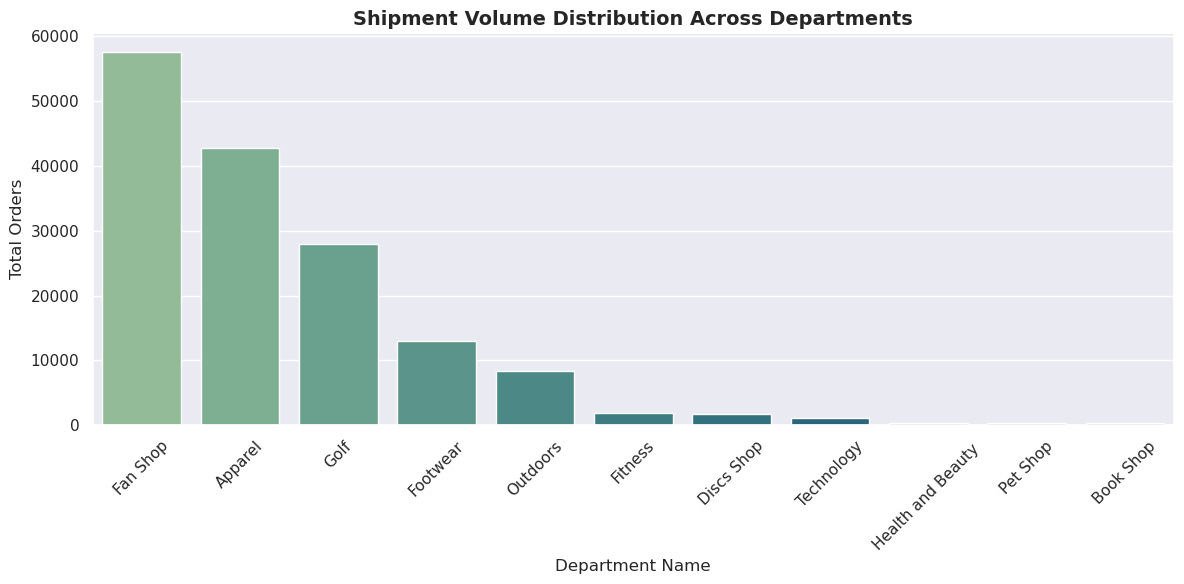

In [9]:
# 5. Department-wise Shipment Volume
sns.set_theme(style='darkgrid')
plt.figure(figsize=(12, 6))
department_counts = df['department_name'].value_counts().reset_index()
department_counts.columns = ['department_name', 'count']

sns.barplot(data=department_counts, x='department_name', y='count', palette='crest')
plt.title('Shipment Volume Distribution Across Departments', fontsize=14, fontweight='bold')
plt.xlabel('Department Name', fontsize=12)
plt.ylabel('Total Orders', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_22105/3122590200.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_profit, x='shipping_mode', y='profit_per_order', palette='Blues_d')


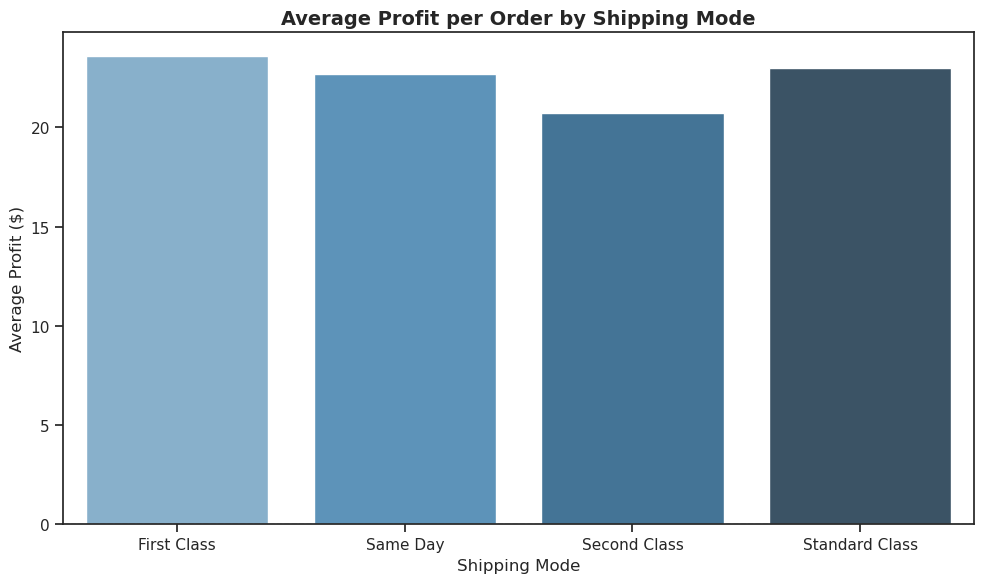

In [14]:
# Calculate average profit per shipping mode
plt.figure(figsize=(10, 6))

avg_profit = df.groupby('shipping_mode')['profit_per_order'].mean().reset_index()

sns.barplot(data=avg_profit, x='shipping_mode', y='profit_per_order', palette='Blues_d')
plt.title('Average Profit per Order by Shipping Mode', fontsize=14, fontweight='bold')
plt.xlabel('Shipping Mode', fontsize=12)
plt.ylabel('Average Profit ($)', fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=1) #
plt.tight_layout()
plt.show()

/tmp/ipykernel_22105/3212639487.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=market_counts, x='market', y='count', palette='crest')


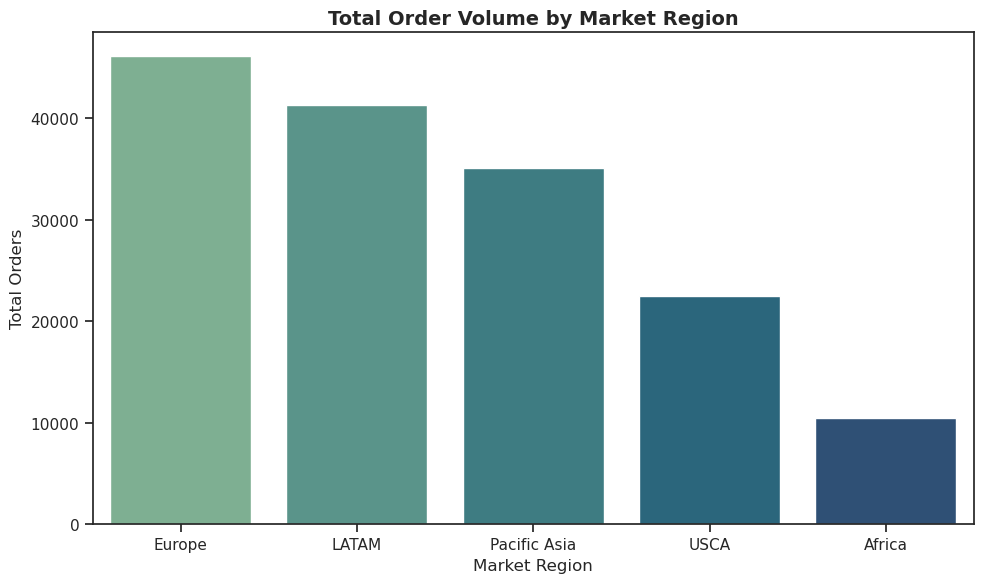

In [15]:
# Get value counts of markets
plt.figure(figsize=(10, 6))

market_counts = df['market'].value_counts().reset_index()
market_counts.columns = ['market', 'count']

sns.barplot(data=market_counts, x='market', y='count', palette='crest')
plt.title('Total Order Volume by Market Region', fontsize=14, fontweight='bold')
plt.xlabel('Market Region', fontsize=12)
plt.ylabel('Total Orders', fontsize=12)
plt.tight_layout()
plt.show()